# 02 - Preprocessing

The EDA (`01_eda.ipynb`) showed that the data need **no classic cleaning**: no missing values, no duplicate
ids, always 6 P1 Pokémon and 30 turns. Battles that look odd (under-levelled Pokémon, unusual species) are
**kept**, because the final evaluation set is private and may contain them too; they are flagged instead.

What we do need is **structural preprocessing**, so that feature engineering works on clean tables:

1. **Normalise the data conventions**: type order and `notype`, `nostatus` / `noeffect` placeholders.
2. **Flatten the timeline and label null moves**: voluntary switch, switch after KO, blocked, other.
3. **Replay the timeline**: final known state of every Pokémon seen, including "vanished" Pokémon.
4. **Variable-power moves**: expected damage estimated from observed HP drops (`src/move_damage.py`).
5. **Species table from train only**, with a fallback for species never seen in train.

The logic lives in `src/preprocessing.py` and `src/move_damage.py`; this notebook runs it, checks it and saves
the tables to `data/processed/`.

> Scaling, imputation and encodings are **not** done here: they learn from the data, so they go inside the
> model `Pipeline` and are fitted on the training fold only.

## 0. Setup

In [1]:
import sys
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Make the repo root importable when running from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data import find_data_dir, load_jsonl
from src.move_damage import fit_move_damage
from src import preprocessing as pp

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

DATA_DIR = find_data_dir()
OUT_DIR = ROOT / "data" / "processed"
OUT_DIR.mkdir(parents=True, exist_ok=True)

train = load_jsonl(DATA_DIR / "train.jsonl")
test = load_jsonl(DATA_DIR / "test.jsonl")
print(f"Data dir: {DATA_DIR.resolve()} | train: {len(train):,} | test: {len(test):,}")

Data dir: D:\FDS Challenge\PokePredict\data\raw | train: 10,000 | test: 5,000


## 1. Normalising the data conventions

- `types` is always a pair padded with `notype`, and `notype` is sometimes listed **first** (e.g. Alakazam is
  `["notype", "psychic"]`), so "first type = primary type" would be wrong for 3,339 P1 Pokémon. We drop
  `notype` and sort, so every Pokémon has a tuple of its real types in a canonical order.
- `nostatus` and `noeffect` are placeholders for "nothing": they become `None`.
- `effects` always holds **exactly one** element: when a Pokémon has two effects at once we only see one.
  This is an information loss in the data, not something we can fix.

In [2]:
raw_types = Counter(tuple(p["types"]) for b in train for p in b["p1_team_details"])
notype_first = sum(n for t, n in raw_types.items() if t[0] == "notype")
print(f"P1 Pokémon with 'notype' listed first: {notype_first:,}")
print("examples:", [(t, pp.normalize_types(t)) for t in [("notype", "psychic"), ("fire", "notype"), ("water", "ice")]])

# Same type combination written in different orders, before vs after normalisation
raw_combos = {frozenset(t) for t in raw_types}
print(f"distinct raw type lists: {len(raw_types)} | after normalisation: {len({pp.normalize_types(t) for t in raw_types})} "
      f"| distinct as sets: {len(raw_combos)}")

n_effects = Counter(len(t[f"{s}_pokemon_state"]["effects"]) for b in train for t in b["battle_timeline"] for s in ("p1", "p2"))
print("length of the effects list:", dict(n_effects))

P1 Pokémon with 'notype' listed first: 3,339
examples: [(('notype', 'psychic'), ('psychic',)), (('fire', 'notype'), ('fire',)), (('water', 'ice'), ('ice', 'water'))]
distinct raw type lists: 55 | after normalisation: 55 | distinct as sets: 55


length of the effects list: {1: 600000}


### 1.1 Static information: P1 team and P2 lead

One row per P1 team member plus one per P2 lead. Under-levelled Pokémon are flagged, not removed.

In [3]:
team_train, team_test = pp.team_frame(train), pp.team_frame(test)
display(team_train.head(7))

under = team_train[team_train["underlevel"]]
print(f"under-levelled Pokémon (train): {len(under)} in {under['battle_id'].nunique()} battles, "
      f"P1: {(under['side'] == 'p1').sum()}, P2 lead: {(under['side'] == 'p2').sum()}")
print("most common levels below 100:", under["level"].value_counts().head(8).to_dict())

,battle_id,side,slot,name,level,types,item,base_hp,base_atk,base_def,base_spa,base_spd,base_spe,player_won,underlevel
0,0,p1,0,tyranitar,100,"(dark, rock)",leftovers,100,134,110,95,100,61,0,False
1,0,p1,1,typhlosion,100,"(fire,)",mintberry,78,84,78,109,85,100,0,False
2,0,p1,2,golem,100,"(ground, rock)",berserkgene,80,110,130,55,65,45,0,False
3,0,p1,3,umbreon,100,"(dark,)",leftovers,95,65,110,60,130,65,0,False
4,0,p1,4,alakazam,100,"(psychic,)",leftovers,55,50,45,135,85,120,0,False
5,0,p1,5,raikou,100,"(electric,)",leftovers,90,85,75,115,100,115,0,False
6,0,p2,0,forretress,100,"(bug, steel)",NaN,75,90,140,60,60,40,0,False


under-levelled Pokémon (train): 422 in 63 battles, P1: 360, P2 lead: 62
most common levels below 100: {5: 248, 16: 18, 58: 16, 35: 13, 40: 9, 10: 9, 15: 8, 50: 8}


## 2. Flattening the timeline and labelling null moves

One row per (battle, turn, side). A null `move_details` mixes different situations, so each turn gets an
`action` label by comparing the active Pokémon with the previous turn:
`move`, `switch after KO`, `voluntary switch`, `blocked (slp/frz/par)` or `other`.

In [4]:
damage_table = fit_move_damage(train)        # train only (see section 4)
tl_train = pp.timeline_frame(train, damage_table)
tl_test = pp.timeline_frame(test, damage_table)
print("timeline train:", tl_train.shape, "| test:", tl_test.shape)
assert len(tl_train) == len(train) * pp.N_TURNS * 2 and len(tl_test) == len(test) * pp.N_TURNS * 2
tl_train.head()

timeline train: (600000, 23) | test: (300000, 23)


,battle_id,turn,side,name,hp_pct,status,effect,boost_atk,boost_def,boost_spa,boost_spd,boost_spe,move,move_type,move_category,move_bp,move_accuracy,move_priority,player_won,expected_damage,prev_status,switched,action
0,0,1,p1,tyranitar,1.00,NaN,NaN,0,0,0,0,0,earthquake,ground,physical,100.0,1.00,0.0,0,0.216737,NaN,False,move
1,0,2,p1,typhlosion,1.00,tox,NaN,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,True,voluntary switch
2,0,3,p1,typhlosion,0.94,tox,NaN,0,0,0,0,0,fireblast,fire,special,120.0,0.85,0.0,0,0.216455,tox,False,move
3,0,4,p1,typhlosion,0.03,tox,NaN,0,0,0,0,0,fireblast,fire,special,120.0,0.85,0.0,0,0.216455,tox,False,move
4,0,5,p1,typhlosion,1.00,NaN,NaN,0,0,0,0,0,rest,psychic,status,0.0,1.00,0.0,0,0.000000,tox,False,move


In [5]:
actions = pd.crosstab(tl_train["action"], tl_train["side"], normalize="columns").round(4)
display(actions)

# "other" null moves: what does the active Pokémon look like on those turns?
other = tl_train[tl_train["action"] == "other"]
print(f"'other' rows: {len(other):,} | turn 1: {(other['turn'] == 1).sum():,} | "
      f"status: {other['status'].fillna('none').value_counts().head(4).to_dict()}")
rest = other[(other["turn"] > 1) & (other["status"] != "fnt")]
print(f"breakdown: turn 1 = {(other['turn'] == 1).sum():,} | active Pokémon fainted = {(other['status'] == 'fnt').sum():,} "
      f"| remaining = {len(rest):,} (recharge, flinch, full paralysis... not distinguishable)")

side,p1,p2
action,,
blocked (frz),0.0004,0.0006
blocked (par),0.0028,0.0028
blocked (slp),0.0063,0.0063
move,0.8021,0.8013
other,0.0126,0.0140
switch after KO,0.0274,0.0073
voluntary switch,0.1484,0.1677


'other' rows: 7,984 | turn 1: 5,295 | status: {'none': 6978, 'fnt': 890, 'tox': 103, 'brn': 10}
breakdown: turn 1 = 5,295 | active Pokémon fainted = 890 | remaining = 1,860 (recharge, flinch, full paralysis... not distinguishable)


## 3. Replaying the timeline: final state of every Pokémon seen

For each battle and side, every Pokémon that appeared gets its final known state: last HP, last status,
whether it fainted, and whether it **vanished** (last seen before turn 30, never marked fainted).
Vanished P2 Pokémon with low HP are the proxy for P2 KOs that are not recorded (EDA, section 5.6).

In [6]:
states_train, states_test = pp.pokemon_states(tl_train), pp.pokemon_states(tl_test)
display(states_train.head())

def side_summary(states, n_battles):
    s = states.assign(vanished_low=states["vanished"] & (states["last_hp"] <= 0.5))
    return (s.groupby("side")[["fainted", "vanished", "vanished_low"]].sum() / n_battles).round(3)

print("per battle (train):"); display(side_summary(states_train, len(train)))
print("per battle (test, descriptive only):"); display(side_summary(states_test, len(test)))

,battle_id,side,name,first_turn,last_turn,turns_active,min_hp,player_won,last_hp,last_status,fainted,vanished
0,0,p1,alakazam,25,28,4,1.00,0,1.00,NaN,False,True
1,0,p1,golem,14,16,3,0.76,0,0.76,NaN,False,True
2,0,p1,typhlosion,2,30,12,0.02,0,1.00,slp,False,False
3,0,p1,tyranitar,1,20,8,0.00,0,0.00,fnt,True,False
4,0,p1,umbreon,21,23,3,0.86,0,0.92,NaN,False,True


per battle (train):


,fainted,vanished,vanished_low
side,,,
p1,1.688,2.81,0.512
p2,0.504,3.92,1.203


per battle (test, descriptive only):


,fainted,vanished,vanished_low
side,,,
p1,1.684,2.829,0.507
p2,0.513,3.909,1.205


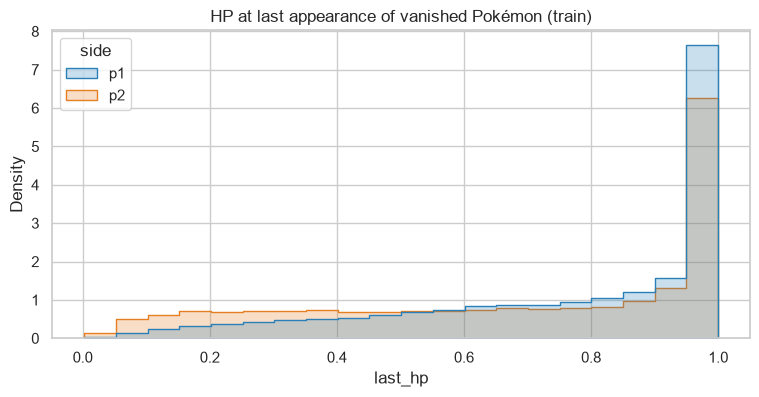

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=states_train[states_train["vanished"]], x="last_hp", hue="side", bins=20, stat="density",
             common_norm=False, element="step", ax=ax, palette={"p1": "#2980b9", "p2": "#e67e22"})
ax.set_title("HP at last appearance of vanished Pokémon (train)"); plt.show()

## 4. Variable-power moves: expected damage from observed HP drops

29,081 damaging moves in train have `base_power = 0` (Hidden Power, Return, Frustration, Seismic Toss,
Counter, ...). Instead of treating them as harmless, `src/move_damage.py` estimates the **expected damage**
of every move from the HP the defender loses on the turns it is used:
- only cleanly attributable turns (same defender, no healing, no Substitute / Protect / Endure);
- the residual drift (poison, burn, Leech Seed, Leftovers) measured on status-move turns is subtracted;
- the mean includes misses, so it is the expected damage given the move's accuracy;
- rare moves (< 30 uses) fall back to a linear fit on base power, or to the mean of variable-power moves.

The estimate never uses `player_won`, so it has no target leakage; it is fitted on train only.

In [8]:
print(f"drift = {damage_table.drift:.4f} | fallback: {damage_table.bp_intercept:.4f} + {damage_table.bp_slope:.5f} * bp "
      f"| variable-power default = {damage_table.variable_default:.3f}")
reliable = damage_table.table[damage_table.table["n"] >= damage_table.min_count]
known = reliable[reliable["base_power"] > 0]
frequent = known[known["n"] >= 200]
print(f"sanity check, corr(base power, observed damage): moves with n >= {damage_table.min_count}: "
      f"{known['base_power'].corr(known['mean']):.3f} | n >= 200: {frequent['base_power'].corr(frequent['mean']):.3f}")
display(reliable[reliable["base_power"] == 0].round(3))

drift = 0.0158 | fallback: -0.0594 + 0.00244 * bp | variable-power default = 0.194
sanity check, corr(base power, observed damage): moves with n >= 30: 0.702 | n >= 200: 0.841


,n,base_power,mean,median,estimate
move,,,,,
hiddenpower,12173,0,0.194,0.154,0.194
return,1665,0,0.228,0.214,0.228
seismictoss,699,0,0.140,0.181,0.140
counter,277,0,0.195,-0.016,0.195
frustration,263,0,0.207,0.174,0.207
mirrorcoat,123,0,0.102,-0.016,0.102
present,97,0,0.100,-0.016,0.100
nightshade,53,0,0.190,0.214,0.190
reversal,53,0,0.390,0.324,0.390


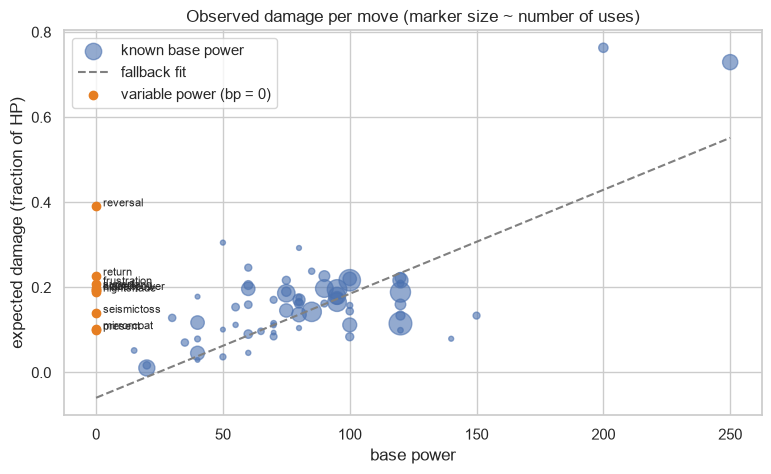

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(known["base_power"], known["mean"], s=np.sqrt(known["n"]) * 2, alpha=0.6, label="known base power")
xs = np.linspace(0, known["base_power"].max(), 50)
ax.plot(xs, damage_table.bp_intercept + damage_table.bp_slope * xs, c="grey", ls="--", label="fallback fit")
var = reliable[reliable["base_power"] == 0]
ax.scatter(np.zeros(len(var)), var["mean"], c="#e67e22", label="variable power (bp = 0)")
for name, row in var.iterrows():
    ax.annotate(name, (0, row["mean"]), xytext=(5, 0), textcoords="offset points", fontsize=8)
ax.set_xlabel("base power"); ax.set_ylabel("expected damage (fraction of HP)")
ax.set_title("Observed damage per move (marker size ~ number of uses)"); ax.legend(); plt.show()

In [10]:
dmg_moves = tl_test[tl_test["move_category"].isin(["physical", "special"])]
print(f"test damaging moves without an expected damage: {dmg_moves['expected_damage'].isna().sum()}")
print(f"test damaging moves with base_power = 0 now get a mean expected damage of "
      f"{dmg_moves.loc[dmg_moves['move_bp'] == 0, 'expected_damage'].mean():.3f}")

test damaging moves without an expected damage: 0
test damaging moves with base_power = 0 now get a mean expected damage of 0.194


## 5. Species table (train only) and fallback for unknown species

Base stats and types are only given for P1's team and P2's lead. For the other P2 Pokémon seen in the
timeline we look them up in a species table built **from the training set only** (P1 teams + P2 leads).
Species never seen in train (e.g. Mega forms in test, which do not exist in Gen 2) get the mean stats and
no types, with a `known_species = False` flag.

In [11]:
species = pp.build_species_table(train)
print(f"species in the table: {len(species)}")

# Consistency: a species must always have the same stats and types in the raw data
check = team_train.groupby("name").agg(n_types=("types", "nunique"), **{f"n_{s}": (s, "nunique") for s in pp.STATS})
print("species with inconsistent stats/types:", int((check > 1).any(axis=1).sum()))

def coverage(tl, team, name):
    seen = pd.Index(tl["name"].unique()).union(team["name"].unique())
    looked = pp.lookup_species(species, seen)
    unknown = looked.index[~looked["known_species"]].tolist()
    print(f"{name}: {len(seen)} species seen, {len(unknown)} unknown -> {unknown}")

coverage(tl_train, team_train, "train")
coverage(tl_test, team_test, "test ")
display(pp.lookup_species(species, ["snorlax", "alakazammega"]))

species in the table: 239
species with inconsistent stats/types: 0
train: 247 species seen, 8 unknown -> ['cleffa', 'horsea', 'ledyba', 'magikarp', 'natu', 'nidorina', 'remoraid', 'unown']


test : 242 species seen, 10 unknown -> ['alakazammega', 'celebi', 'charizardmegay', 'cleffa', 'horsea', 'kakuna', 'magikarp', 'natu', 'unown', 'weedle']


,types,n_seen,base_hp,base_atk,base_def,base_spa,base_spd,base_spe,known_species
name,,,,,,,,,
snorlax,"(normal,)",9984,160.000000,110.000000,65.00000,65.000000,110.000000,30.000000,True
alakazammega,(),0,67.322176,71.556485,69.09205,66.615063,68.937238,66.175732,False


## 6. Saving the processed tables

In [12]:
import pickle

outputs = {
    "team_train.pkl": team_train, "team_test.pkl": team_test,
    "timeline_train.pkl": tl_train, "timeline_test.pkl": tl_test,
    "states_train.pkl": states_train, "states_test.pkl": states_test,
    "species_table.pkl": species,
}
for fname, df in outputs.items():
    df.to_pickle(OUT_DIR / fname)
with open(OUT_DIR / "move_damage.pkl", "wb") as f:
    pickle.dump(damage_table, f)
for p in sorted(OUT_DIR.glob("*.pkl")):
    print(f"{p.name:22s} {p.stat().st_size / 1e6:6.1f} MB")

move_damage.pkl           0.0 MB
species_table.pkl         0.0 MB
states_test.pkl           3.6 MB
states_train.pkl          7.9 MB
team_test.pkl             4.0 MB
team_train.pkl            8.4 MB
timeline_test.pkl        51.1 MB
timeline_train.pkl      106.5 MB


## 7. Summary

| Step | Output | Notes |
|---|---|---|
| Conventions | normalised `types`, `status`, `effect` | `effects` holds one element only: information loss in the data |
| Static info | `team_*.pkl` | under-levelled Pokémon flagged (`underlevel`), not removed |
| Timeline | `timeline_*.pkl` | `action` label for every turn, `expected_damage` for every move |
| Replay | `states_*.pkl` | final state per Pokémon, `vanished` flag (P2 KO proxy) |
| Variable-power moves | `move_damage.pkl` | fitted on train only, no target used |
| Species | `species_table.pkl` | train only; unknown species -> mean stats, `known_species = False` |

All tables are built in the same way for train and test. The `.pkl` files are not versioned (`.gitignore`):
re-run this notebook to regenerate them. Next step: feature engineering (`03_features.ipynb`).